# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial. 
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Nina Breen, Marin Marcillac, Claire McGinn, Roney Nguyen

**Date:** 11/16/26

1. Check out the data set `heart_failure` and appropriately clean it.


In [1]:
import pandas as pd


df = pd.read_csv("data/heart_failure/heart_failure_clinical_records_dataset.csv")
print("Shape:", df.shape)
print(df.isna().sum())
print("Data types", df.dtypes)
df = df.dropna()
df.head()
# The dataset has 299 rows and 13 columns with 0 missing values in any column.
# The variables are numeric (int64 or float64)
#The binary columns  like anaemia, diabetes, sex, and smoking are coded binary 0 or 1.
#made sure with the dropna 

Shape: (299, 13)
age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64
Data types age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


array([[<Axes: title={'center': 'age'}>,
        <Axes: title={'center': 'anaemia'}>,
        <Axes: title={'center': 'creatinine_phosphokinase'}>,
        <Axes: title={'center': 'diabetes'}>],
       [<Axes: title={'center': 'ejection_fraction'}>,
        <Axes: title={'center': 'high_blood_pressure'}>,
        <Axes: title={'center': 'platelets'}>,
        <Axes: title={'center': 'serum_creatinine'}>],
       [<Axes: title={'center': 'serum_sodium'}>,
        <Axes: title={'center': 'sex'}>,
        <Axes: title={'center': 'smoking'}>,
        <Axes: title={'center': 'time'}>],
       [<Axes: title={'center': 'DEATH_EVENT'}>, <Axes: >, <Axes: >,
        <Axes: >]], dtype=object)

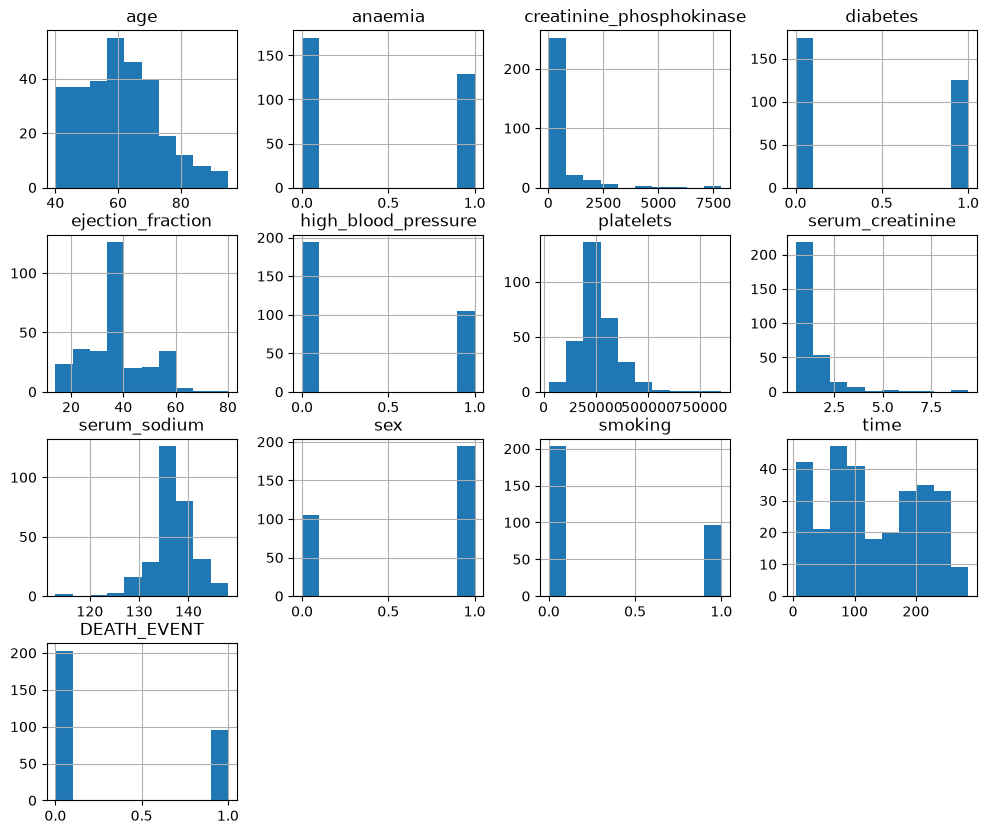

In [2]:
df.hist(figsize=(12, 10))
#for fun just wanted to see)

2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler


eval_x_raw = df.drop(columns=['DEATH_EVENT'])
eval_y = df['DEATH_EVENT']

(x_train, x_test, y_train, y_test,) = train_test_split(eval_x_raw, eval_y, test_size=0.20, random_state=100)

scaler = MinMaxScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [4]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

tree_model = DecisionTreeClassifier(max_depth=3, random_state=100)
tree_model.fit(x_train, y_train)

tree_preds_base = tree_model.predict(x_test)

print("Tree Accuracy - train:", round(tree_model.score(x_train, y_train), 4))
print("Tree Accuracy - test:", round(accuracy_score(y_test, tree_preds_base), 4))

Tree Accuracy - train: 0.8912
Tree Accuracy - test: 0.7833


In [5]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression()
log_model.fit(x_train, y_train)

log_preds_base = log_model.predict(x_test)

print("Logistic Accuracy - train:", round(log_model.score(x_train, y_train), 4))
print("Logistic Accuracy - test:", round(accuracy_score(y_test, log_preds_base), 4))

Logistic Accuracy - train: 0.8536
Logistic Accuracy - test: 0.7667


In [6]:
# Using random_state=100 for the 80/20 split and predicting ejection fraction.
# Both models have smaller test accuracies, so neither model predicted
# death events well on this test set.
# Both models perform better on the training data than on the test data,
# which could suggest overfitting.

3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.

Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial. 
But are they?

In [7]:
alt_tree_preds = {}
alt_log_preds = {}
alt_tree_models = {}

seeds = [101, 102, 103, 104]

for seed in seeds:
    x_train_s, x_test_s, y_train_s, y_test_s = train_test_split(
        eval_x_raw, eval_y, test_size=0.20, random_state=seed
    )
    
    scaler_s = MinMaxScaler()
    x_train_s = scaler_s.fit_transform(x_train_s)    

    tree_model_s = DecisionTreeClassifier(max_depth=3, random_state=100)
    tree_model_s.fit(x_train_s, y_train_s)
    
    log_model_s = LogisticRegression(solver='saga', max_iter=10000, random_state=100)
    log_model_s.fit(x_train_s, y_train_s)
    
    alt_tree_preds[seed] = tree_model_s.predict(x_test)
    alt_log_preds[seed] = log_model_s.predict(x_test)
    alt_tree_models[seed] = tree_model_s
    
    x_test_s_scaled = scaler_s.transform(x_test_s)
    print(f"--- Data Split Seed: {seed} ---")
    print(f"Tree Accuracy - test: {round(accuracy_score(y_test_s, tree_model_s.predict(x_test_s_scaled)), 4)}")
    print(f"Logistic Accuracy - test: {round(accuracy_score(y_test_s, log_model_s.predict(x_test_s_scaled)), 4)}")
    print(f"Logistic coefs: {log_model_s.coef_[0].round(4)}\n")

--- Data Split Seed: 101 ---
Tree Accuracy - test: 0.9167
Logistic Accuracy - test: 0.9
Logistic coefs: [ 1.6016  0.0659  0.7894  0.0389 -2.2608  0.1089  0.0665  1.7029 -0.5853
 -0.2314  0.073  -3.2975]

--- Data Split Seed: 102 ---
Tree Accuracy - test: 0.85
Logistic Accuracy - test: 0.8667
Logistic coefs: [ 1.3238  0.1337  0.6909  0.0732 -2.0136  0.0925 -0.0448  1.7133 -0.6323
 -0.0416 -0.1553 -3.3392]

--- Data Split Seed: 103 ---
Tree Accuracy - test: 0.85
Logistic Accuracy - test: 0.8833
Logistic coefs: [ 1.519   0.1115  0.5349  0.1401 -1.9624  0.0468 -0.3874  1.4368 -0.8892
 -0.3945  0.1258 -3.3855]

--- Data Split Seed: 104 ---
Tree Accuracy - test: 0.7833
Logistic Accuracy - test: 0.8167
Logistic coefs: [ 1.6622  0.0706  0.5766  0.0608 -2.1865 -0.1315 -0.3247  1.6686 -1.35
 -0.2526  0.1197 -3.0425]



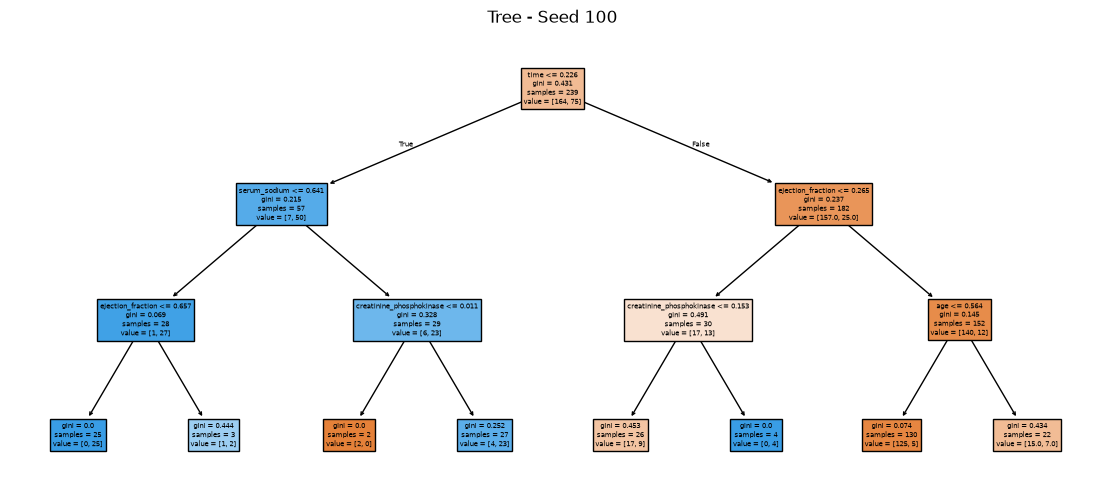

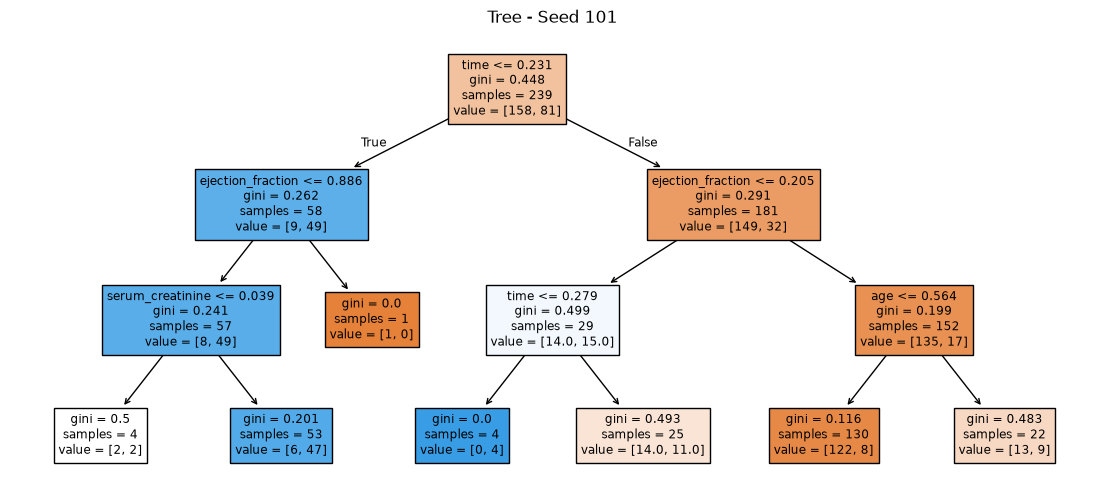

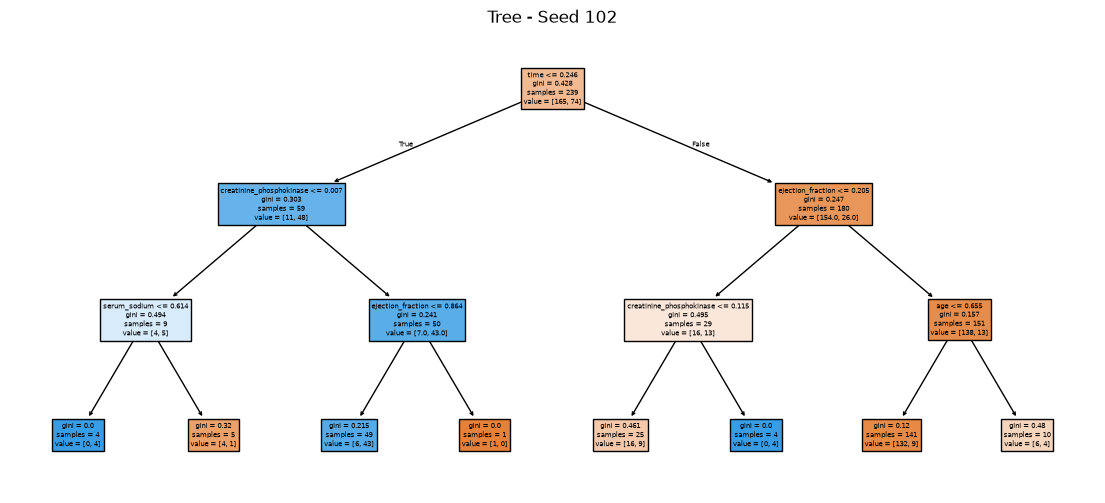

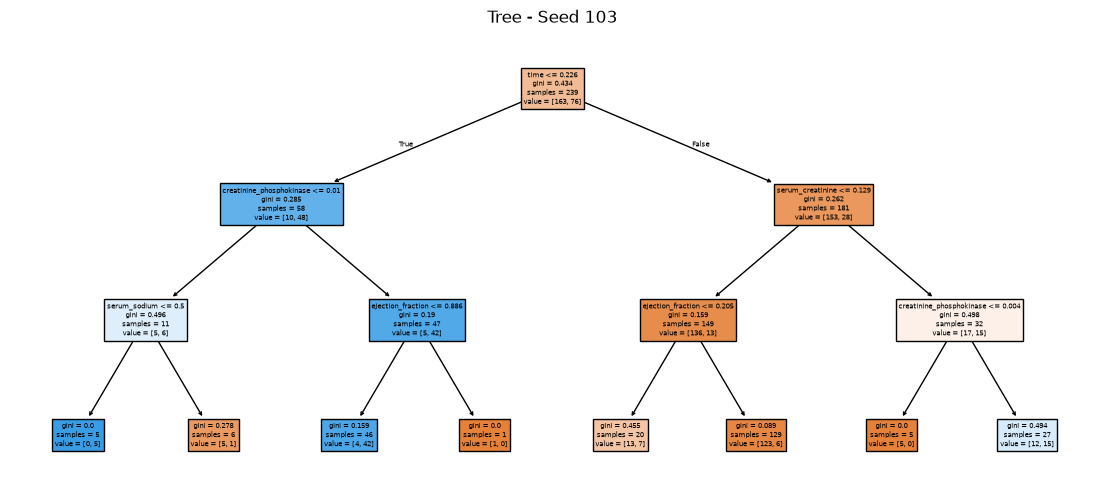

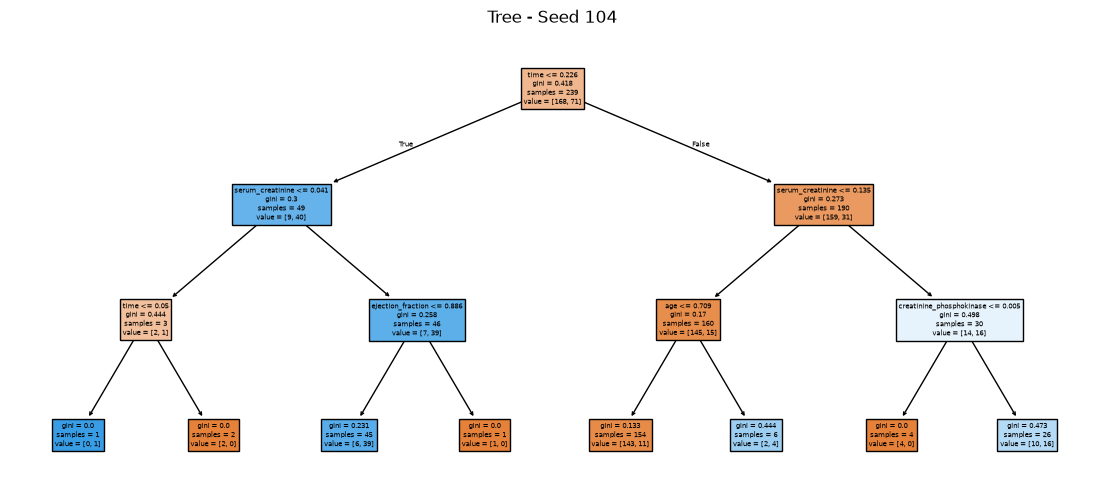

In [8]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))
plot_tree(tree_model, feature_names=eval_x_raw.columns, filled=True)
plt.title("Tree - Seed 100")
plt.show()

for seed in seeds:
    plt.figure(figsize=(14, 6))
    plot_tree(alt_tree_models[seed], feature_names=eval_x_raw.columns, filled=True)
    plt.title(f"Tree - Seed {seed}")
    plt.show()

In [9]:
# How different are the linear model coefficients?
# Some coefficients stay fairly similar across seeds 101–104, while others
# change more or change signs.

# How different are the trees?
# The trees for all seeds all start with time, but their
# lower branches change across the different train-test splits.
# For example, the left branch uses serum_sodium for seed 100,
# ejection_fraction for seed 101, and creatine_phosphokinase for seed 102.

# This shows that the modes are sensitive to random noise and split the data differently, which can lead to different trees and coefficients.

4. Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

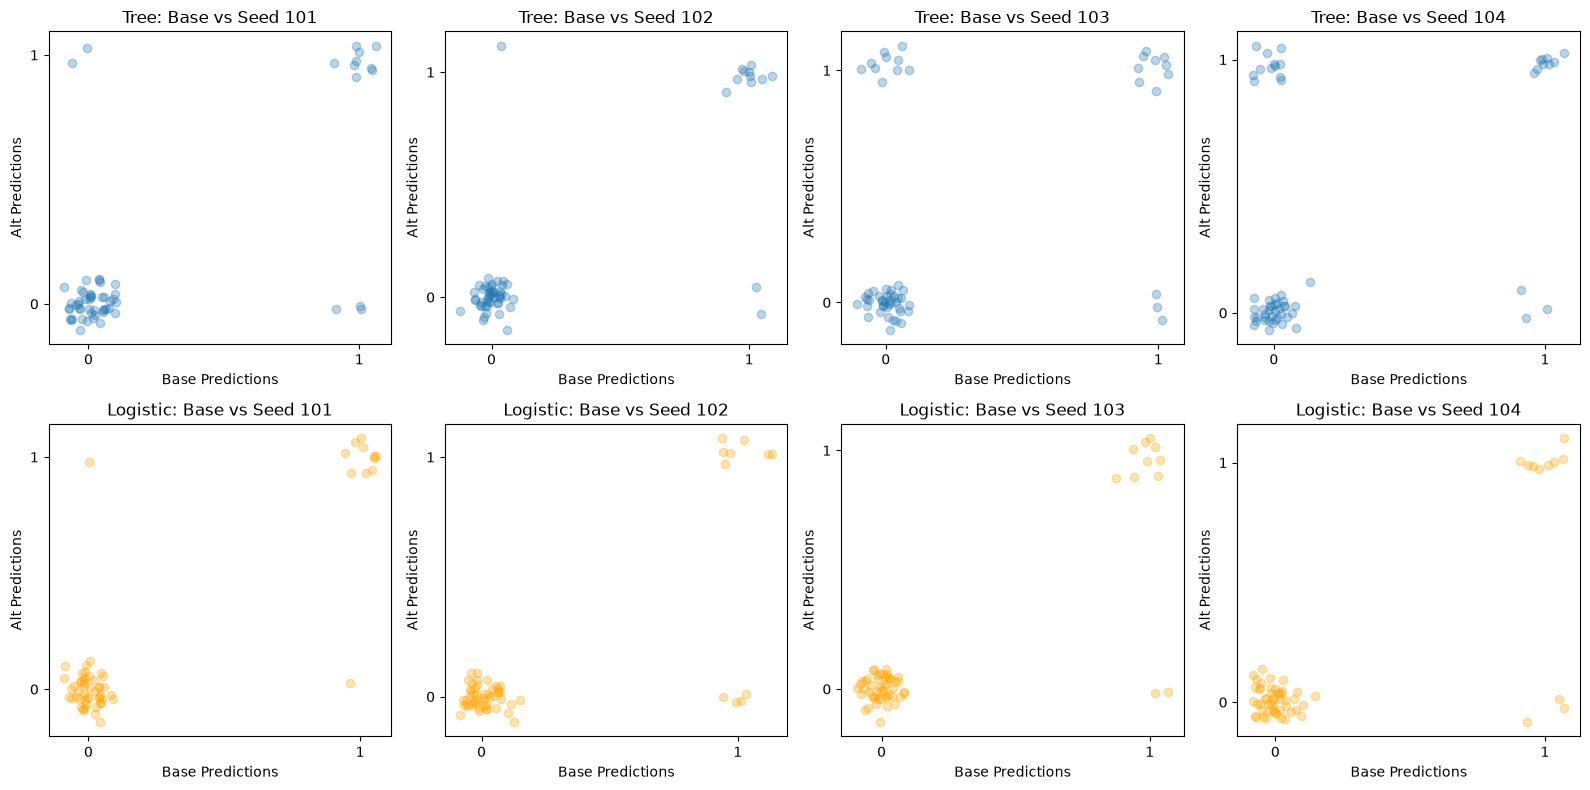

In [10]:
import numpy as np

seeds = [101, 102, 103, 104]

fig, axes = plt.subplots(2, len(seeds), figsize=(16, 8))

def add_jitter(arr, sd=0.05):
    return arr + np.random.normal(0, sd, size=len(arr))

for i, seed in enumerate(seeds):
    
    x_tree = add_jitter(tree_preds_base)
    y_tree = add_jitter(alt_tree_preds[seed])
    
    axes[0, i].scatter(x_tree, y_tree, alpha=0.3)
    axes[0, i].set_title(f"Tree: Base vs Seed {seed}")
    axes[0, i].set_xlabel("Base Predictions")
    axes[0, i].set_ylabel("Alt Predictions")
    axes[0, i].set_xticks([0, 1])
    axes[0, i].set_yticks([0, 1])

    x_log = add_jitter(log_preds_base)
    y_log = add_jitter(alt_log_preds[seed])
    
    axes[1, i].scatter(x_log, y_log, alpha=0.3, color='orange')
    axes[1, i].set_title(f"Logistic: Base vs Seed {seed}")
    axes[1, i].set_xlabel("Base Predictions")
    axes[1, i].set_ylabel("Alt Predictions")
    axes[1, i].set_xticks([0, 1])
    axes[1, i].set_yticks([0, 1])

plt.tight_layout()
plt.show()

In [11]:
# Do they appear reasonably similar?
# The linear model predictions look pretty similar across seeds since the points that were predicted are the same between seeds. 
# The decision tree scatterplots have more spread in teh corners that have different predictions and is highly variable across seeds, 
# which is consistent with the trees being more sensitive to random noise and different train-test splits.

In [12]:
for seed in seeds:
    tree_corr = np.corrcoef(tree_preds_base, alt_tree_preds[seed])[0, 1]
    log_corr = np.corrcoef(log_preds_base, alt_log_preds[seed])[0, 1]
    print(f"Seed {seed}: \nTree Corr = {tree_corr:.4f} \nLogistic Corr = {log_corr:.4f}")

Seed 101: 
Tree Corr = 0.7322 
Logistic Corr = 0.8887
Seed 102: 
Tree Corr = 0.8399 
Logistic Corr = 0.7670
Seed 103: 
Tree Corr = 0.4658 
Logistic Corr = 0.8866
Seed 104: 
Tree Corr = 0.4193 
Logistic Corr = 0.8278


In [13]:
# Are they highly correlated or not?
# The linear model predictions are strongly correlated with the base model across all seeds.
# This shows that the linear model predictions tend to move together even when the train-test split changes.

# The decision tree correlations with the base tree are lower and more variable.
# This shows that the tree predictions are less strongly related to the base tree's predictions when the split changes.

In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

X_tree_base = tree_preds_base.reshape(-1, 1)
X_log_base = log_preds_base.reshape(-1, 1)

reg = LinearRegression()

for seed in seeds:
    print(f"--- Data Split Seed: {seed} ---")
    
    reg.fit(X_tree_base, alt_tree_preds[seed])
    tree_intercept = reg.intercept_
    tree_slope = reg.coef_[0]
    tree_r2 = r2_score(alt_tree_preds[seed], reg.predict(X_tree_base))
    
    print(f"Decision Tree - Intercept: {tree_intercept:.4f}, Slope: {tree_slope:.4f}, R^2: {tree_r2:.4f}")
    
    reg.fit(X_log_base, alt_log_preds[seed])
    log_intercept = reg.intercept_
    log_slope = reg.coef_[0]
    log_r2 = r2_score(alt_log_preds[seed], reg.predict(X_log_base))
    
    print(f"Logistic Reg  - Intercept: {log_intercept:.4f}, Slope: {log_slope:.4f}, R^2: {log_r2:.4f}\n")

--- Data Split Seed: 101 ---
Decision Tree - Intercept: 0.0417, Slope: 0.7083, R^2: 0.5362
Logistic Reg  - Intercept: 0.0204, Slope: 0.8887, R^2: 0.7898

--- Data Split Seed: 102 ---
Decision Tree - Intercept: 0.0208, Slope: 0.8125, R^2: 0.7055
Logistic Reg  - Intercept: 0.0000, Slope: 0.6364, R^2: 0.5883

--- Data Split Seed: 103 ---
Decision Tree - Intercept: 0.2083, Slope: 0.5417, R^2: 0.2169
Logistic Reg  - Intercept: 0.0000, Slope: 0.8182, R^2: 0.7861

--- Data Split Seed: 104 ---
Decision Tree - Intercept: 0.2500, Slope: 0.5000, R^2: 0.1758
Logistic Reg  - Intercept: 0.0000, Slope: 0.7273, R^2: 0.6853



In [15]:
# for the linear models, the intercepts are close to 0, slops are closer to 1 
# than the decision tree, and the R^2 values are close to 1 except for seed 102.
# For the dicision trees, the intercepts are further from 0, slopes are a variety of values, 
# and the R^2 values are very low and variable across seeds. 

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?

In [16]:
# Linear models are more stable and have similar coefficients and predictions across different train/test splits.
# Decision trees are less stable and have more variable coefficients and predictions across different train/test splits.

6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

In [17]:
# False - as the scatterplot in question 4 shows, the decision tree plots
# do not typically agree on predictions across different train/test splits.
# The linear model predictions are similar, but that is because their appearance (eg coeficients)
# remain the same across splits.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [18]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]